# VLM and Goal-Directed Attention


This notebook analyzes direct VLM outputs (model answers) for both Qwen (Qwen3-VL-32B-Instruct) and Gemma (Gemma-4-26B-A4B-it).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats
from PIL import Image

# analysis/ is the parent of notebooks/
ANALYSIS = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ANALYSIS))
from helpers import runs as R, util as U
from helpers.util import gm  # repo-root gaze_metrics
print("data dir:", R.DATA_DIR)
MODELS = ["qwen-instruct", "gemma"]

data dir: /Users/hanzh/Documents/Github/VLM-gaze/analysis/data


## Target-Present Images

In [3]:
# Locate the target-present run IDs used for each model and task.
tp_runs = []

for model in MODELS:
    for goal in ["search", "free"]:
        runs = U.get_run_ids(model, condition="tp", goal=goal)
        tp_runs.append({"model": model, "condition": "tp", "goal": goal, "runs": runs})

pd.DataFrame(tp_runs)

,model,condition,goal,runs
0,qwen-instruct,tp,search,"[63889206, 63889207]"
1,qwen-instruct,tp,free,"[63889208, 63889209]"
2,gemma,tp,search,"[64991404, 58387155]"
3,gemma,tp,free,"[58411643, 58387156]"


### Qwen / Model Answer

In [4]:
# Qwen, target-present: read model predictions and human fixations.

# get the run ids
qwen_output_search_runs = U.get_run_ids("qwen-instruct", condition="tp", goal="search")
qwen_output_free_runs = U.get_run_ids("qwen-instruct", condition="tp", goal="free")

# get the model predictions
qwen_output_search_predictions = U.load_fixations(qwen_output_search_runs, mode="vlm")
qwen_output_free_predictions = U.load_fixations(qwen_output_free_runs, mode="vlm")

# get the human fixations
qwen_output_search_human_fixations = U.load_fixations(qwen_output_search_runs, mode="human")
qwen_output_free_human_fixations = U.load_fixations(qwen_output_free_runs, mode="human")

# Count unique pictures by the task/name image key used in the analysis files.
print("Qwen output search | N images:", qwen_output_search_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Qwen output free | N images:", qwen_output_free_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Qwen output search | N images:", qwen_output_search_human_fixations[["task", "name"]].drop_duplicates().shape[0])
print("Qwen output free | N images:", qwen_output_free_human_fixations[["task", "name"]].drop_duplicates().shape[0])

Qwen output search | N images: 2476
Qwen output free | N images: 2476
Qwen output search | N images: 2476
Qwen output free | N images: 2476


In [5]:
qwen_output_search_predictions.head(5)

,mode,condition,task,name,iw,ih,seq,rank,x1000,y1000,x_px,y_px,region,run
0,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,0,109,446,152.6,468.3,red bottle on left side of desk,63889206
1,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,1,655,250,917.0,262.5,small container near window,63889206
2,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,2,298,498,417.2,522.9,glass on desk,63889206
3,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,3,875,252,1225.0,264.6,cup near window,63889206
4,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,1,0,109,446,152.6,468.3,red bottle on left side of desk,63889206


In [6]:
qwen_output_search_human_fixations.head(5)

,task,name,iw,ih,kind,x_px,y_px,run
0,bottle,000000019544.jpg,1400,1050,search,701.4,343.3,63889206
1,bottle,000000019544.jpg,1400,1050,search,974.9,534.9,63889206
2,bottle,000000019544.jpg,1400,1050,search,406.9,525.2,63889206
3,bottle,000000019544.jpg,1400,1050,search,160.1,499.2,63889206
4,bottle,000000019544.jpg,1400,1050,search,158.4,441.9,63889206


In [7]:
# Qwen, target-present: compute density maps per picture.
qwen_output_search_density_maps = U.density_maps_from_points(
    data=qwen_output_search_predictions,
    mode="vlm"
)
qwen_output_free_density_maps = U.density_maps_from_points(
    data=qwen_output_free_predictions,
    mode="vlm"
)

qwen_output_search_human_density_maps = U.density_maps_from_points(
    data=qwen_output_search_human_fixations,
    mode="human",
    goal="search"
)
qwen_output_free_human_density_maps = U.density_maps_from_points(
    data=qwen_output_free_human_fixations,
    mode="human",
    goal="free"
)

print("Qwen output search maps:", len(qwen_output_search_density_maps))
print("Qwen output free maps:", len(qwen_output_free_density_maps))
print("Qwen output search human maps:", len(qwen_output_search_human_density_maps))
print("Qwen output free human maps:", len(qwen_output_free_human_density_maps))

Qwen output search maps: 2476
Qwen output free maps: 2476
Qwen output search human maps: 2474
Qwen output free human maps: 2476


In [8]:
# Compute per-picture correlations for the Qwen 2x2 comparison.
correlation_rows = []

# get a common set of pictures that exist in all four maps
shared_pictures = sorted(
    set(qwen_output_search_density_maps)
    & set(qwen_output_free_density_maps)
    & set(qwen_output_search_human_density_maps)
    & set(qwen_output_free_human_density_maps)
)

for target, name in shared_pictures:
    qwen_search_map = qwen_output_search_density_maps[(target, name)]
    qwen_free_map = qwen_output_free_density_maps[(target, name)]
    human_search_map = qwen_output_search_human_density_maps[(target, name)]
    human_free_map = qwen_output_free_human_density_maps[(target, name)]

    map_pairs = [
        ("search", "search", qwen_search_map, human_search_map),
        ("search", "free", qwen_search_map, human_free_map),
        ("free", "search", qwen_free_map, human_search_map),
        ("free", "free", qwen_free_map, human_free_map),
    ]

    for qwen_goal, human_goal, qwen_map, human_map in map_pairs:
        correlation_rows.append(
            {
                "target": target,
                "name": name,
                "qwen_goal": qwen_goal,
                "human_goal": human_goal,
                "correlation": gm.cc(qwen_map, human_map),
            }
        )

qwen_output_correlations = pd.DataFrame(correlation_rows)
qwen_output_correlations.head(5)

,target,name,qwen_goal,human_goal,correlation
0,bottle,000000001455.jpg,search,search,0.949018
1,bottle,000000001455.jpg,search,free,0.079202
2,bottle,000000001455.jpg,free,search,0.466493
3,bottle,000000001455.jpg,free,free,0.607535
4,bottle,000000009527.jpg,search,search,0.867259


In [9]:
# mean and sd for each group
qwen_output_correlations.groupby(["qwen_goal", "human_goal"])["correlation"].agg(['mean', 'std']).reset_index()


,qwen_goal,human_goal,mean,std
0,free,free,0.443630,0.171299
1,free,search,0.329111,0.179017
2,search,free,0.161525,0.222598
3,search,search,0.729881,0.181097


In [10]:
# Repeated-measures ANOVA for the Qwen 2x2 design.
qwen_output_anova_data = qwen_output_correlations.copy()
qwen_output_anova_data["picture"] = (
    qwen_output_anova_data["target"] + " / " + qwen_output_anova_data["name"]
)

qwen_output_rmanova = pg.rm_anova(
    data=qwen_output_anova_data,
    dv="correlation",
    within=["qwen_goal", "human_goal"],
    subject="picture",
    detailed=True,
)

qwen_output_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,qwen_goal,8.709330,1,2473,8.709330,338.472048,6.008002e-71,6.008002e-71,0.023916,1.0
1,human_goal,127.391460,1,2473,127.391460,4243.162330,0.000000e+00,0.000000e+00,0.263832,1.0
2,qwen_goal * human_goal,288.417173,1,2473,288.417173,10334.361228,0.000000e+00,0.000000e+00,0.447938,1.0


In [11]:
# Pairwise tests: compare human_goal within each level of qwen_goal.
pairwise_results = []

for qwen_goal, goal_data in qwen_output_anova_data.groupby("qwen_goal", sort=False):
    paired_goals = (
        goal_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    pairwise_results.append(
        {
            "qwen_goal": qwen_goal,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

qwen_output_pairwise_tests = pd.DataFrame(pairwise_results)
qwen_output_pairwise_tests[
    ["qwen_goal", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,qwen_goal,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,115.689040,2473,two-sided,0.000000e+00,2.801009,0.559,0.578
1,free,search,free,-24.037794,2473,two-sided,6.414231e-115,0.653642,-0.124,-0.105


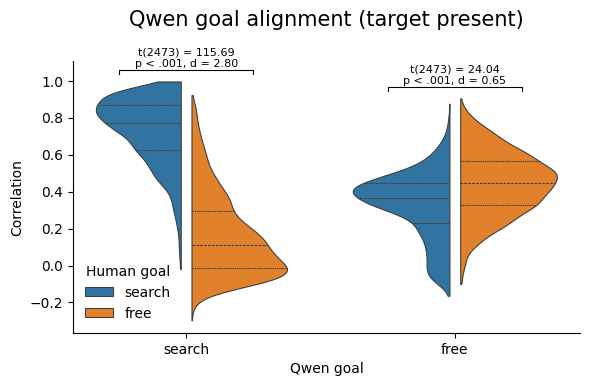

In [12]:
# Violin plot: per-picture correlations for each 2x2 cell.
qwen_goal_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(qwen_goal_order))

sns.violinplot(
    data=qwen_output_correlations,
    x="qwen_goal",
    y="correlation",
    hue="human_goal",
    order=qwen_goal_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = qwen_output_correlations["correlation"].max()
annotation_step = 0.05

for qwen_index, qwen_goal in enumerate(qwen_goal_order):
    pairwise_row = qwen_output_pairwise_tests[
        qwen_output_pairwise_tests["qwen_goal"] == qwen_goal
    ].iloc[0]

    x_left = x_positions[qwen_index] - 0.25
    x_right = x_positions[qwen_index] + 0.25
    y_base = qwen_output_correlations.loc[
        qwen_output_correlations["qwen_goal"] == qwen_goal,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Qwen goal")
ax.set_ylabel("Correlation")
ax.set_title("Qwen goal alignment (target present)", y=1.1, fontsize=15)
ax.set_ylim(top=annotation_top)
ax.legend(title="Human goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
qwen_output_violin_fig = fig

### Gemma / Model Answer


In [13]:
# Gemma, target-present: read model predictions and human fixations.

# get the run ids
gemma_output_search_runs = U.get_run_ids("gemma", condition="tp", goal="search")
gemma_output_free_runs = U.get_run_ids("gemma", condition="tp", goal="free")

# get the model predictions
gemma_output_search_predictions = U.load_fixations(gemma_output_search_runs, mode="vlm")
gemma_output_free_predictions = U.load_fixations(gemma_output_free_runs, mode="vlm")

# get the human fixations
gemma_output_search_human_fixations = U.load_fixations(gemma_output_search_runs, mode="human")
gemma_output_free_human_fixations = U.load_fixations(gemma_output_free_runs, mode="human")

print("Gemma output search | N images:", gemma_output_search_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Gemma output free | N images:", gemma_output_free_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Gemma output search human | N images:", gemma_output_search_human_fixations[["task", "name"]].drop_duplicates().shape[0])
print("Gemma output free human | N images:", gemma_output_free_human_fixations[["task", "name"]].drop_duplicates().shape[0])

Gemma output search | N images: 2476
Gemma output free | N images: 2476
Gemma output search human | N images: 2476
Gemma output free human | N images: 2476


In [14]:
gemma_output_search_predictions.head(5)

,mode,condition,task,name,iw,ih,seq,rank,x1000,y1000,x_px,y_px,region,run
0,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,0,113,449,158.2,471.4,the red bottle on the left,64991404
1,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,1,297,499,415.8,524.0,the glass on the desk,64991404
2,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,0,2,873,261,1222.2,274.1,the small cup/glass in the background,64991404
3,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,1,0,111,449,155.4,471.4,the red bottle on the left,64991404
4,scanpath,scanpath,bottle,000000019544.jpg,1400,1050,1,1,298,500,417.2,525.0,the glass on the desk,64991404


In [15]:
gemma_output_search_human_fixations.head(5)

,task,name,iw,ih,kind,x_px,y_px,run
0,bottle,000000019544.jpg,1400,1050,search,701.4,343.3,64991404
1,bottle,000000019544.jpg,1400,1050,search,974.9,534.9,64991404
2,bottle,000000019544.jpg,1400,1050,search,406.9,525.2,64991404
3,bottle,000000019544.jpg,1400,1050,search,160.1,499.2,64991404
4,bottle,000000019544.jpg,1400,1050,search,158.4,441.9,64991404


In [16]:
# Gemma, target-present: compute density maps per picture.
# Reuses shared density-map helpers from helpers.util.
gemma_output_search_density_maps = U.density_maps_from_points(
    data=gemma_output_search_predictions,
    mode="vlm"
)
gemma_output_free_density_maps = U.density_maps_from_points(
    data=gemma_output_free_predictions,
    mode="vlm"
)

gemma_output_search_human_density_maps = U.density_maps_from_points(
    data=gemma_output_search_human_fixations,
    mode="human",
    goal="search"
)
gemma_output_free_human_density_maps = U.density_maps_from_points(
    data=gemma_output_free_human_fixations,
    mode="human",
    goal="free"
)

print("Gemma output search maps:", len(gemma_output_search_density_maps))
print("Gemma output free maps:", len(gemma_output_free_density_maps))
print("Gemma output search human maps:", len(gemma_output_search_human_density_maps))
print("Gemma output free human maps:", len(gemma_output_free_human_density_maps))

Gemma output search maps: 2476
Gemma output free maps: 2476
Gemma output search human maps: 2474
Gemma output free human maps: 2476


In [17]:
# Compute per-picture correlations for the Gemma 2x2 comparison.
gemma_correlation_rows = []

# get a common set of pictures that exist in all four maps
gemma_shared_pictures = sorted(
    set(gemma_output_search_density_maps)
    & set(gemma_output_free_density_maps)
    & set(gemma_output_search_human_density_maps)
    & set(gemma_output_free_human_density_maps)
)

for target, name in gemma_shared_pictures:
    gemma_search_map = gemma_output_search_density_maps[(target, name)]
    gemma_free_map = gemma_output_free_density_maps[(target, name)]
    human_search_map = gemma_output_search_human_density_maps[(target, name)]
    human_free_map = gemma_output_free_human_density_maps[(target, name)]

    map_pairs = [
        ("search", "search", gemma_search_map, human_search_map),
        ("search", "free", gemma_search_map, human_free_map),
        ("free", "search", gemma_free_map, human_search_map),
        ("free", "free", gemma_free_map, human_free_map),
    ]

    for gemma_goal, human_goal, gemma_map, human_map in map_pairs:
        gemma_correlation_rows.append(
            {
                "target": target,
                "name": name,
                "gemma_goal": gemma_goal,
                "human_goal": human_goal,
                "correlation": gm.cc(gemma_map, human_map),
            }
        )

gemma_output_correlations = pd.DataFrame(gemma_correlation_rows)
gemma_output_correlations

,target,name,gemma_goal,human_goal,correlation
0,bottle,000000001455.jpg,search,search,0.943770
1,bottle,000000001455.jpg,search,free,0.090746
2,bottle,000000001455.jpg,free,search,0.456498
3,bottle,000000001455.jpg,free,free,0.577863
4,bottle,000000009527.jpg,search,search,0.784619
...,...,...,...,...,...
9891,tv,000000579186.jpg,free,free,0.498587
9892,tv,000000580392.jpg,search,search,0.621001
9893,tv,000000580392.jpg,search,free,-0.050271
9894,tv,000000580392.jpg,free,search,0.376406


In [18]:
# mean and sd for each group
gemma_output_correlations.groupby(["gemma_goal", "human_goal"])["correlation"].agg(['mean', 'std']).reset_index()

,gemma_goal,human_goal,mean,std
0,free,free,0.425986,0.189042
1,free,search,0.306680,0.190163
2,search,free,0.164616,0.223378
3,search,search,0.702977,0.201395


In [19]:
# Repeated-measures ANOVA for the Gemma 2x2 design.
gemma_output_anova_data = gemma_output_correlations.copy()
gemma_output_anova_data["picture"] = (
    gemma_output_anova_data["target"] + " / " + gemma_output_anova_data["name"]
)

gemma_output_rmanova = pg.rm_anova(
    data=gemma_output_anova_data,
    dv="correlation",
    within=["gemma_goal", "human_goal"],
    subject="picture",
    detailed=True,
)

gemma_output_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,gemma_goal,11.259919,1,2473,11.259919,367.626084,1.672003e-76,1.672003e-76,0.027279,1.0
1,human_goal,108.613032,1,2473,108.613032,3202.533693,0.000000e+00,0.000000e+00,0.212916,1.0
2,gemma_goal * human_goal,267.516949,1,2473,267.516949,9457.192265,0.000000e+00,0.000000e+00,0.399861,1.0


In [20]:
# Pairwise tests: compare human_goal within each level of gemma_goal.
gemma_pairwise_results = []

for gemma_goal, goal_data in gemma_output_anova_data.groupby("gemma_goal", sort=False):
    paired_goals = (
        goal_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    gemma_pairwise_results.append(
        {
            "gemma_goal": gemma_goal,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

gemma_output_pairwise_tests = pd.DataFrame(gemma_pairwise_results)
gemma_output_pairwise_tests[
    ["gemma_goal", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,gemma_goal,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,108.845221,2473,two-sided,0.000000e+00,2.531429,0.529,0.548
1,free,search,free,-23.479016,2473,two-sided,3.231867e-110,0.629238,-0.129,-0.109


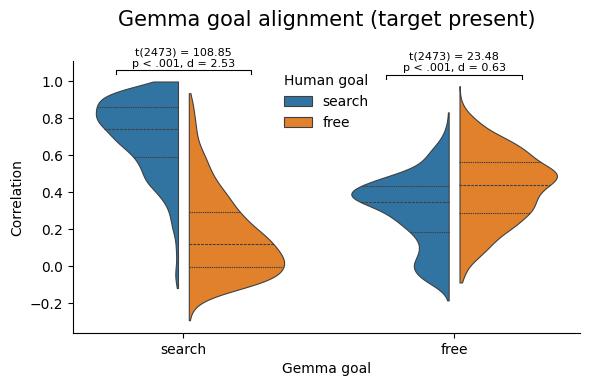

In [21]:
# Violin plot: per-picture correlations for each Gemma 2x2 cell.
gemma_goal_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(gemma_goal_order))

sns.violinplot(
    data=gemma_output_correlations,
    x="gemma_goal",
    y="correlation",
    hue="human_goal",
    order=gemma_goal_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = gemma_output_correlations["correlation"].max()
annotation_step = 0.05

for gemma_index, gemma_goal in enumerate(gemma_goal_order):
    pairwise_row = gemma_output_pairwise_tests[
        gemma_output_pairwise_tests["gemma_goal"] == gemma_goal
    ].iloc[0]

    x_left = x_positions[gemma_index] - 0.25
    x_right = x_positions[gemma_index] + 0.25
    y_base = gemma_output_correlations.loc[
        gemma_output_correlations["gemma_goal"] == gemma_goal,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Gemma goal")
ax.set_ylabel("Correlation")
ax.set_title("Gemma goal alignment (target present)", y=1.1, fontsize=15)
ax.set_ylim(top=annotation_top)
ax.legend(title="Human goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
gemma_output_violin_fig = fig

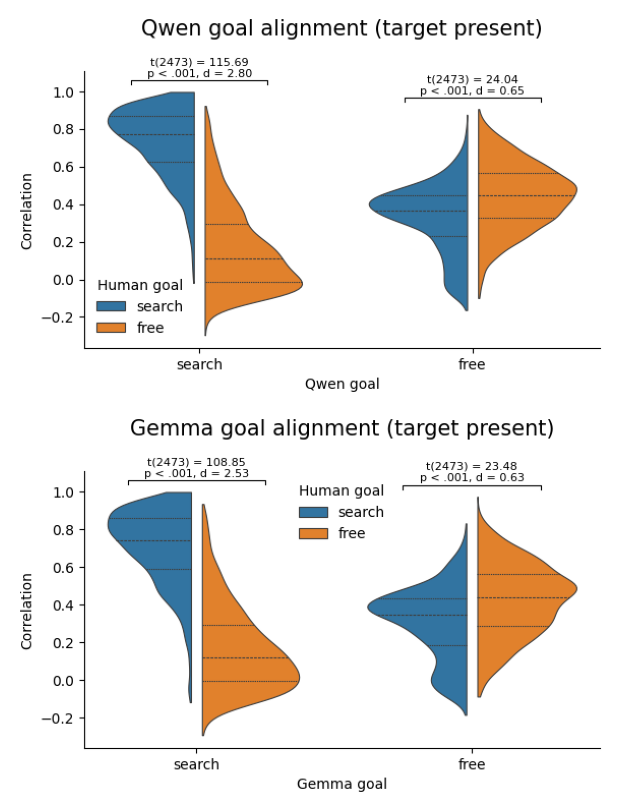

In [22]:
# Stack the already-created Qwen and Gemma violin figures into one image.
from io import BytesIO


def figure_to_image(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi, bbox_inches="tight")
    buffer.seek(0)
    return np.asarray(Image.open(buffer).convert("RGB"))


qwen_output_violin_image = figure_to_image(qwen_output_violin_fig)
gemma_output_violin_image = figure_to_image(gemma_output_violin_fig)

fig, axes = plt.subplots(2, 1, figsize=(6, 8))

for ax, image in zip(
    axes,
    [qwen_output_violin_image, gemma_output_violin_image],
):
    ax.imshow(image)
    ax.axis("off")

fig.tight_layout(pad=0)

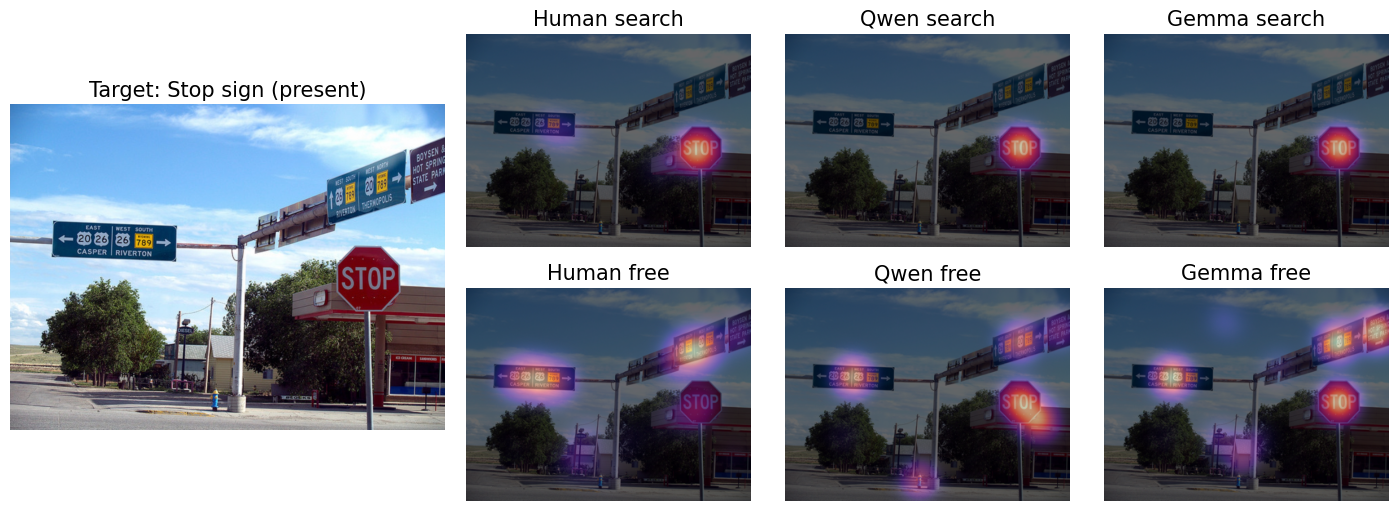

In [23]:
# Plot one example image's density maps for the search/free human and Gemma outputs.
example_picture = ("stop sign", "000000493682.jpg")
example_image_path = ANALYSIS.parent / "data" / "COCO-Search18" / "TP-images" / example_picture[0] / example_picture[1]
example_image = Image.open(example_image_path).convert("RGB")
example_image, _, _ = gm.crop_letterbox(example_image)

example_maps = [
    ("Human search", gemma_output_search_human_density_maps[example_picture]),
    ("Qwen search", qwen_output_search_density_maps[example_picture]),
    ("Gemma search", gemma_output_search_density_maps[example_picture]),
    ("Human free", gemma_output_free_human_density_maps[example_picture]),
    ("Qwen free", qwen_output_free_density_maps[example_picture]),
    ("Gemma free", gemma_output_free_density_maps[example_picture]),
]

fig = plt.figure(figsize=(14, 5), constrained_layout=True)
grid = fig.add_gridspec(
    2,
    4,
    width_ratios=[1.4, 1, 1, 1],
    wspace=0,
    hspace=0,
)

original_ax = fig.add_subplot(grid[:, 0])
original_ax.imshow(example_image)
original_ax.set_title("Target: Stop sign (present)", fontsize=15)
original_ax.axis("off")

axes = [fig.add_subplot(grid[row, col]) for row in range(2) for col in range(1, 4)]

for ax, (title, density) in zip(axes, example_maps):
    plot_image = example_image.resize((density.shape[1], density.shape[0]))

    ax.imshow(plot_image, alpha=1)
    ax.imshow(density, cmap="magma", vmin=0, vmax=1, alpha=0.6)
    ax.set_title(title, fontsize=15)
    ax.axis("off")

## Target-Absent Images


In [24]:
# Locate the target-absent run IDs used for each model and task.
ta_runs = []

for model in MODELS:
    for goal in ["search", "free"]:
        runs = U.get_run_ids(model, condition="ta", goal=goal)
        ta_runs.append({"model": model, "condition": "ta", "goal": goal, "runs": runs})

pd.DataFrame(ta_runs)

,model,condition,goal,runs
0,qwen-instruct,ta,search,"[63889202, 63889203]"
1,qwen-instruct,ta,free,"[63889204, 63889205]"
2,gemma,ta,search,"[64991402, 58387153]"
3,gemma,ta,free,"[64991403, 58387154]"


### Qwen / Model Answer


In [25]:
# Qwen, target-absent: read model predictions and human fixations.
qwen_ta_output_search_runs = U.get_run_ids("qwen-instruct", condition="ta", goal="search")
qwen_ta_output_free_runs = U.get_run_ids("qwen-instruct", condition="ta", goal="free")

qwen_ta_output_search_predictions = U.load_fixations(qwen_ta_output_search_runs, mode="vlm")
qwen_ta_output_free_predictions = U.load_fixations(qwen_ta_output_free_runs, mode="vlm")

qwen_ta_output_search_human_fixations = U.load_fixations(qwen_ta_output_search_runs, mode="human")
qwen_ta_output_free_human_fixations = U.load_fixations(qwen_ta_output_free_runs, mode="human")

# Count unique pictures by the task/name image key used in the analysis files.
print("Qwen TA output search predictions | N images:", qwen_ta_output_search_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Qwen TA output free predictions | N images:", qwen_ta_output_free_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Qwen TA output search human fixations | N images:", qwen_ta_output_search_human_fixations[["task", "name"]].drop_duplicates().shape[0])
print("Qwen TA output free human fixations | N images:", qwen_ta_output_free_human_fixations[["task", "name"]].drop_duplicates().shape[0])

Qwen TA output search predictions | N images: 2416
Qwen TA output free predictions | N images: 2416
Qwen TA output search human fixations | N images: 2416
Qwen TA output free human fixations | N images: 2416


In [26]:
qwen_ta_output_search_predictions.head(5)

,mode,condition,task,name,iw,ih,seq,rank,x1000,y1000,x_px,y_px,region,run
0,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,0,950,62,1596.0,58.7,glass stemware in upper right corner,63889202
1,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,1,868,52,1458.2,49.2,area near the base of the glass stemware,63889202
2,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,2,923,372,1550.6,352.3,beige napkin area to the right of the bo,63889202
3,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,3,130,219,218.4,207.4,dark surface behind the bowls,63889202
4,scanpath,scanpath,bottle,000000005600.jpg,1680,947,1,0,922,54,1549.0,51.1,background area near glassware,63889202


In [27]:
qwen_ta_output_search_human_fixations.head(5)

,task,name,iw,ih,kind,x_px,y_px,run
0,bottle,000000005600.jpg,1680,947,search,1564.9,88.9,63889202
1,bottle,000000005600.jpg,1680,947,search,1461.3,42.3,63889202
2,bottle,000000005600.jpg,1680,947,search,765.0,615.8,63889202
3,bottle,000000005600.jpg,1680,947,search,522.8,520.0,63889202
4,bottle,000000005600.jpg,1680,947,search,1475.8,103.0,63889202


In [28]:
# Qwen, target-absent: compute density maps per picture.
# Reuses shared density-map helpers from helpers.util.
qwen_ta_output_search_density_maps = U.density_maps_from_points(
    data=qwen_ta_output_search_predictions,
    mode="vlm"
)
qwen_ta_output_free_density_maps = U.density_maps_from_points(
    data=qwen_ta_output_free_predictions,
    mode="vlm"
)

qwen_ta_output_search_human_density_maps = U.density_maps_from_points(
    data=qwen_ta_output_search_human_fixations,
    mode="human",
    goal="search"
)
qwen_ta_output_free_human_density_maps = U.density_maps_from_points(
    data=qwen_ta_output_free_human_fixations,
    mode="human",
    goal="free"
)

print("Qwen TA output search maps:", len(qwen_ta_output_search_density_maps))
print("Qwen TA output free maps:", len(qwen_ta_output_free_density_maps))
print("Qwen TA output search human maps:", len(qwen_ta_output_search_human_density_maps))
print("Qwen TA output free human maps:", len(qwen_ta_output_free_human_density_maps))

Qwen TA output search maps: 2416
Qwen TA output free maps: 2416
Qwen TA output search human maps: 2413
Qwen TA output free human maps: 2416


In [29]:
# Compute per-picture correlations for the Qwen target-absent 2x2 comparison.
qwen_ta_correlation_rows = []

qwen_ta_shared_pictures = sorted(
    set(qwen_ta_output_search_density_maps)
    & set(qwen_ta_output_free_density_maps)
    & set(qwen_ta_output_search_human_density_maps)
    & set(qwen_ta_output_free_human_density_maps)
)

for target, name in qwen_ta_shared_pictures:
    qwen_search_map = qwen_ta_output_search_density_maps[(target, name)]
    qwen_free_map = qwen_ta_output_free_density_maps[(target, name)]
    human_search_map = qwen_ta_output_search_human_density_maps[(target, name)]
    human_free_map = qwen_ta_output_free_human_density_maps[(target, name)]

    map_pairs = [
        ("search", "search", qwen_search_map, human_search_map),
        ("search", "free", qwen_search_map, human_free_map),
        ("free", "search", qwen_free_map, human_search_map),
        ("free", "free", qwen_free_map, human_free_map),
    ]

    for qwen_goal, human_goal, qwen_map, human_map in map_pairs:
        qwen_ta_correlation_rows.append(
            {
                "target": target,
                "name": name,
                "qwen_goal": qwen_goal,
                "human_goal": human_goal,
                "correlation": gm.cc(qwen_map, human_map),
            }
        )

qwen_ta_output_correlations = pd.DataFrame(qwen_ta_correlation_rows)
qwen_ta_output_correlations.head(5)

,target,name,qwen_goal,human_goal,correlation
0,bottle,000000000196.jpg,search,search,0.178551
1,bottle,000000000196.jpg,search,free,-0.086779
2,bottle,000000000196.jpg,free,search,0.148503
3,bottle,000000000196.jpg,free,free,0.294531
4,bottle,000000003992.jpg,search,search,0.648577


In [30]:
# Mean and SD for each target-absent Qwen 2x2 cell.
qwen_ta_output_correlations.groupby(["qwen_goal", "human_goal"])["correlation"].agg(["mean", "std"]).reset_index()

,qwen_goal,human_goal,mean,std
0,free,free,0.439042,0.163015
1,free,search,0.295048,0.180919
2,search,free,0.234321,0.251272
3,search,search,0.462599,0.236379


In [31]:
# Repeated-measures ANOVA for the Qwen target-absent 2x2 design.
qwen_ta_output_anova_data = qwen_ta_output_correlations.copy()
qwen_ta_output_anova_data["picture"] = (
    qwen_ta_output_anova_data["target"] + " / " + qwen_ta_output_anova_data["name"]
)

qwen_ta_output_rmanova = pg.rm_anova(
    data=qwen_ta_output_anova_data,
    dv="correlation",
    within=["qwen_goal", "human_goal"],
    subject="picture",
    detailed=True,
)

qwen_ta_output_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,qwen_goal,0.833417,1,2412,0.833417,13.961849,1.908887e-04,1.908887e-04,0.001934,1.0
1,human_goal,4.285404,1,2412,4.285404,196.877759,4.715061e-43,4.715061e-43,0.009865,1.0
2,qwen_goal * human_goal,83.601915,1,2412,83.601915,3331.514100,0.000000e+00,0.000000e+00,0.162743,1.0


In [32]:
# Pairwise tests: compare human_goal within each target-absent Qwen goal.
qwen_ta_pairwise_results = []

for qwen_goal, goal_data in qwen_ta_output_anova_data.groupby("qwen_goal", sort=False):
    paired_goals = (
        goal_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    qwen_ta_pairwise_results.append(
        {
            "qwen_goal": qwen_goal,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

qwen_ta_output_pairwise_tests = pd.DataFrame(qwen_ta_pairwise_results)
qwen_ta_output_pairwise_tests[
    ["qwen_goal", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,qwen_goal,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,47.440230,2412,two-sided,0.000000e+00,0.935799,0.219,0.238
1,free,search,free,-36.356739,2412,two-sided,3.689626e-231,0.836199,-0.152,-0.136


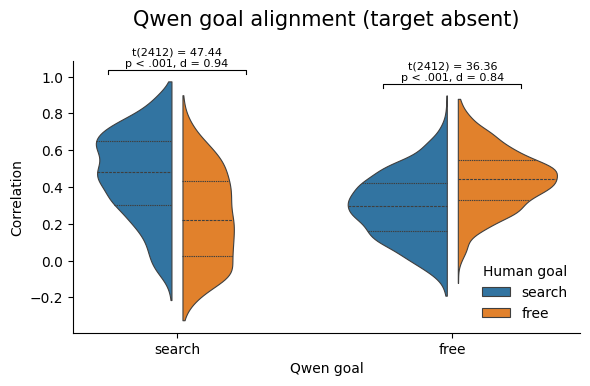

In [33]:
# Violin plot: per-picture correlations for each target-absent Qwen 2x2 cell.
qwen_goal_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(qwen_goal_order))

sns.violinplot(
    data=qwen_ta_output_correlations,
    x="qwen_goal",
    y="correlation",
    hue="human_goal",
    order=qwen_goal_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = qwen_ta_output_correlations["correlation"].max()
annotation_step = 0.05

for qwen_index, qwen_goal in enumerate(qwen_goal_order):
    pairwise_row = qwen_ta_output_pairwise_tests[
        qwen_ta_output_pairwise_tests["qwen_goal"] == qwen_goal
    ].iloc[0]

    x_left = x_positions[qwen_index] - 0.25
    x_right = x_positions[qwen_index] + 0.25
    y_base = qwen_ta_output_correlations.loc[
        qwen_ta_output_correlations["qwen_goal"] == qwen_goal,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Qwen goal")
ax.set_ylabel("Correlation")
ax.set_title("Qwen goal alignment (target absent)", y=1.1, fontsize=15)
ax.set_ylim(top=annotation_top)
ax.legend(title="Human goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
qwen_ta_output_violin_fig = fig

### Gemma / Model Answer


In [34]:
# Gemma, target-absent: read model predictions and human fixations.
gemma_ta_output_search_runs = U.get_run_ids("gemma", condition="ta", goal="search")
gemma_ta_output_free_runs = U.get_run_ids("gemma", condition="ta", goal="free")

gemma_ta_output_search_predictions = U.load_fixations(gemma_ta_output_search_runs, mode="vlm")
gemma_ta_output_free_predictions = U.load_fixations(gemma_ta_output_free_runs, mode="vlm")

gemma_ta_output_search_human_fixations = U.load_fixations(gemma_ta_output_search_runs, mode="human")
gemma_ta_output_free_human_fixations = U.load_fixations(gemma_ta_output_free_runs, mode="human")

# Count unique pictures by the task/name image key used in the analysis files.
print("Gemma TA output search predictions | N images:", gemma_ta_output_search_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Gemma TA output free predictions | N images:", gemma_ta_output_free_predictions[["task", "name"]].drop_duplicates().shape[0])
print("Gemma TA output search human fixations | N images:", gemma_ta_output_search_human_fixations[["task", "name"]].drop_duplicates().shape[0])
print("Gemma TA output free human fixations | N images:", gemma_ta_output_free_human_fixations[["task", "name"]].drop_duplicates().shape[0])

Gemma TA output search predictions | N images: 2367
Gemma TA output free predictions | N images: 2416
Gemma TA output search human fixations | N images: 2416
Gemma TA output free human fixations | N images: 2416


In [35]:
gemma_ta_output_search_predictions.head(5)

,mode,condition,task,name,iw,ih,seq,rank,x1000,y1000,x_px,y_px,region,run
0,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,0,858,140,1441.4,132.6,the background area,64991402
1,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,1,951,42,1597.7,39.8,the top right corner,64991402
2,scanpath,scanpath,bottle,000000005600.jpg,1680,947,0,2,937,894,1574.2,846.6,the bottom right corner,64991402
3,scanpath,scanpath,bottle,000000005600.jpg,1680,947,1,0,950,30,1596.0,28.4,the top right corner area,64991402
4,scanpath,scanpath,bottle,000000005600.jpg,1680,947,1,1,950,950,1596.0,899.6,the bottom right corner area,64991402


In [36]:
gemma_ta_output_search_human_fixations.head(5)

,task,name,iw,ih,kind,x_px,y_px,run
0,bottle,000000005600.jpg,1680,947,search,1564.9,88.9,64991402
1,bottle,000000005600.jpg,1680,947,search,1461.3,42.3,64991402
2,bottle,000000005600.jpg,1680,947,search,765.0,615.8,64991402
3,bottle,000000005600.jpg,1680,947,search,522.8,520.0,64991402
4,bottle,000000005600.jpg,1680,947,search,1475.8,103.0,64991402


In [37]:
# Gemma, target-absent: compute density maps per picture.
# Reuses shared density-map helpers from helpers.util.
gemma_ta_output_search_density_maps = U.density_maps_from_points(
    data=gemma_ta_output_search_predictions,
    mode="vlm"
)
gemma_ta_output_free_density_maps = U.density_maps_from_points(
    data=gemma_ta_output_free_predictions,
    mode="vlm"
)

gemma_ta_output_search_human_density_maps = U.density_maps_from_points(
    data=gemma_ta_output_search_human_fixations,
    mode="human",
    goal="search"
)
gemma_ta_output_free_human_density_maps = U.density_maps_from_points(
    data=gemma_ta_output_free_human_fixations,
    mode="human",
    goal="free"
)

print("Gemma TA output search maps:", len(gemma_ta_output_search_density_maps))
print("Gemma TA output free maps:", len(gemma_ta_output_free_density_maps))
print("Gemma TA output search human maps:", len(gemma_ta_output_search_human_density_maps))
print("Gemma TA output free human maps:", len(gemma_ta_output_free_human_density_maps))

Gemma TA output search maps: 2367
Gemma TA output free maps: 2416
Gemma TA output search human maps: 2413
Gemma TA output free human maps: 2416


In [38]:
# Compute per-picture correlations for the Gemma target-absent 2x2 comparison.
gemma_ta_correlation_rows = []

gemma_ta_shared_pictures = sorted(
    set(gemma_ta_output_search_density_maps)
    & set(gemma_ta_output_free_density_maps)
    & set(gemma_ta_output_search_human_density_maps)
    & set(gemma_ta_output_free_human_density_maps)
)

for target, name in gemma_ta_shared_pictures:
    gemma_search_map = gemma_ta_output_search_density_maps[(target, name)]
    gemma_free_map = gemma_ta_output_free_density_maps[(target, name)]
    human_search_map = gemma_ta_output_search_human_density_maps[(target, name)]
    human_free_map = gemma_ta_output_free_human_density_maps[(target, name)]

    map_pairs = [
        ("search", "search", gemma_search_map, human_search_map),
        ("search", "free", gemma_search_map, human_free_map),
        ("free", "search", gemma_free_map, human_search_map),
        ("free", "free", gemma_free_map, human_free_map),
    ]

    for gemma_goal, human_goal, gemma_map, human_map in map_pairs:
        gemma_ta_correlation_rows.append(
            {
                "target": target,
                "name": name,
                "gemma_goal": gemma_goal,
                "human_goal": human_goal,
                "correlation": gm.cc(gemma_map, human_map),
            }
        )

gemma_ta_output_correlations = pd.DataFrame(gemma_ta_correlation_rows)
gemma_ta_output_correlations.head(5)

,target,name,gemma_goal,human_goal,correlation
0,bottle,000000000196.jpg,search,search,-0.087133
1,bottle,000000000196.jpg,search,free,-0.022937
2,bottle,000000000196.jpg,free,search,0.105399
3,bottle,000000000196.jpg,free,free,0.279988
4,bottle,000000003992.jpg,search,search,0.189763


In [39]:
# Mean and SD for each target-absent Gemma 2x2 cell.
gemma_ta_output_correlations.groupby(["gemma_goal", "human_goal"])["correlation"].agg(["mean", "std"]).reset_index()

,gemma_goal,human_goal,mean,std
0,free,free,0.417362,0.187726
1,free,search,0.269901,0.187349
2,search,free,0.224571,0.239475
3,search,search,0.398029,0.243456


In [40]:
# Repeated-measures ANOVA for the Gemma target-absent 2x2 design.
gemma_ta_output_anova_data = gemma_ta_output_correlations.copy()
gemma_ta_output_anova_data["picture"] = (
    gemma_ta_output_anova_data["target"] + " / " + gemma_ta_output_anova_data["name"]
)

gemma_ta_output_rmanova = pg.rm_anova(
    data=gemma_ta_output_anova_data,
    dv="correlation",
    within=["gemma_goal", "human_goal"],
    subject="picture",
    detailed=True,
)

gemma_ta_output_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,gemma_goal,2.471033,1,2363,2.471033,36.597558,1.683525e-09,1.683525e-09,0.005562,1.0
1,human_goal,0.399428,1,2363,0.399428,17.142228,3.589936e-05,3.589936e-05,0.000903,1.0
2,gemma_goal * human_goal,60.866536,1,2363,60.866536,2371.250696,0.000000e+00,0.000000e+00,0.121091,1.0


In [41]:
# Pairwise tests: compare human_goal within each target-absent Gemma goal.
gemma_ta_pairwise_results = []

for gemma_goal, goal_data in gemma_ta_output_anova_data.groupby("gemma_goal", sort=False):
    paired_goals = (
        goal_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    gemma_ta_pairwise_results.append(
        {
            "gemma_goal": gemma_goal,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

gemma_ta_output_pairwise_tests = pd.DataFrame(gemma_ta_pairwise_results)
gemma_ta_output_pairwise_tests[
    ["gemma_goal", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,gemma_goal,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,35.028021,2363,two-sided,7.188353e-217,0.718332,0.164,0.183
1,free,search,free,-35.862653,2363,two-sided,2.897234e-225,0.786301,-0.156,-0.139


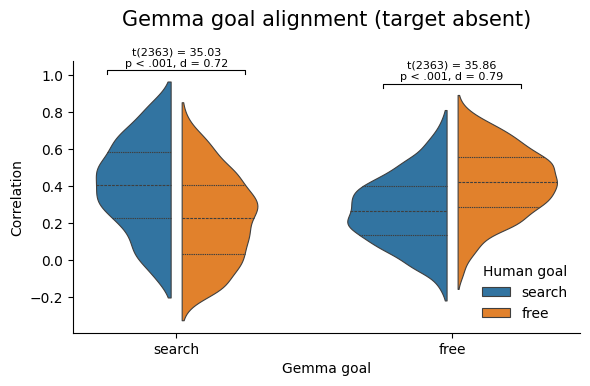

In [42]:
# Violin plot: per-picture correlations for each target-absent Gemma 2x2 cell.
gemma_goal_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(gemma_goal_order))

sns.violinplot(
    data=gemma_ta_output_correlations,
    x="gemma_goal",
    y="correlation",
    hue="human_goal",
    order=gemma_goal_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = gemma_ta_output_correlations["correlation"].max()
annotation_step = 0.05

for gemma_index, gemma_goal in enumerate(gemma_goal_order):
    pairwise_row = gemma_ta_output_pairwise_tests[
        gemma_ta_output_pairwise_tests["gemma_goal"] == gemma_goal
    ].iloc[0]

    x_left = x_positions[gemma_index] - 0.25
    x_right = x_positions[gemma_index] + 0.25
    y_base = gemma_ta_output_correlations.loc[
        gemma_ta_output_correlations["gemma_goal"] == gemma_goal,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Gemma goal")
ax.set_ylabel("Correlation")
ax.set_title("Gemma goal alignment (target absent)", y=1.1, fontsize=15)
ax.set_ylim(top=annotation_top)
ax.legend(title="Human goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
gemma_ta_output_violin_fig = fig

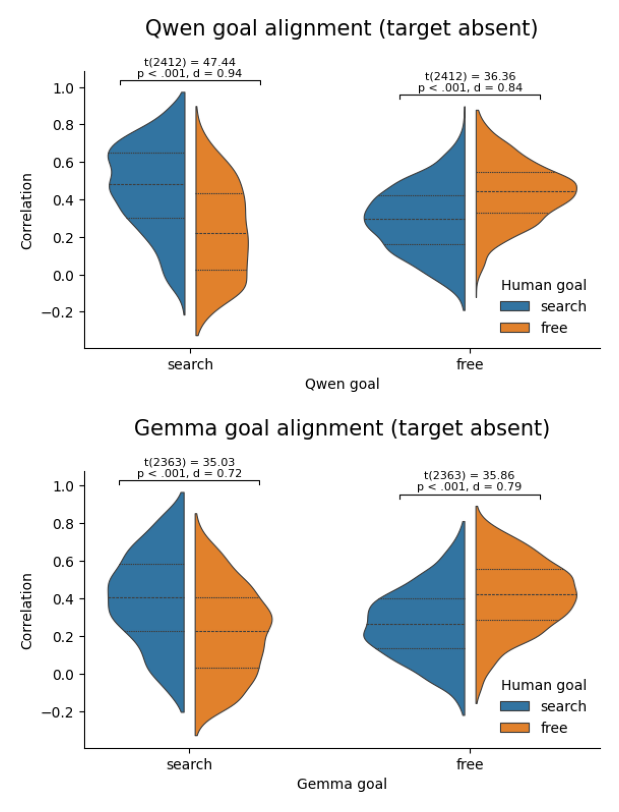

In [43]:
# Stack the already-created target-absent Qwen and Gemma violin figures into one image.
from io import BytesIO


def figure_to_image(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi, bbox_inches="tight")
    buffer.seek(0)
    return np.asarray(Image.open(buffer).convert("RGB"))


qwen_ta_output_violin_image = figure_to_image(qwen_ta_output_violin_fig)
gemma_ta_output_violin_image = figure_to_image(gemma_ta_output_violin_fig)

fig, axes = plt.subplots(2, 1, figsize=(6, 8))

for ax, image in zip(
    axes,
    [qwen_ta_output_violin_image, gemma_ta_output_violin_image],
):
    ax.imshow(image)
    ax.axis("off")

fig.tight_layout(pad=0)


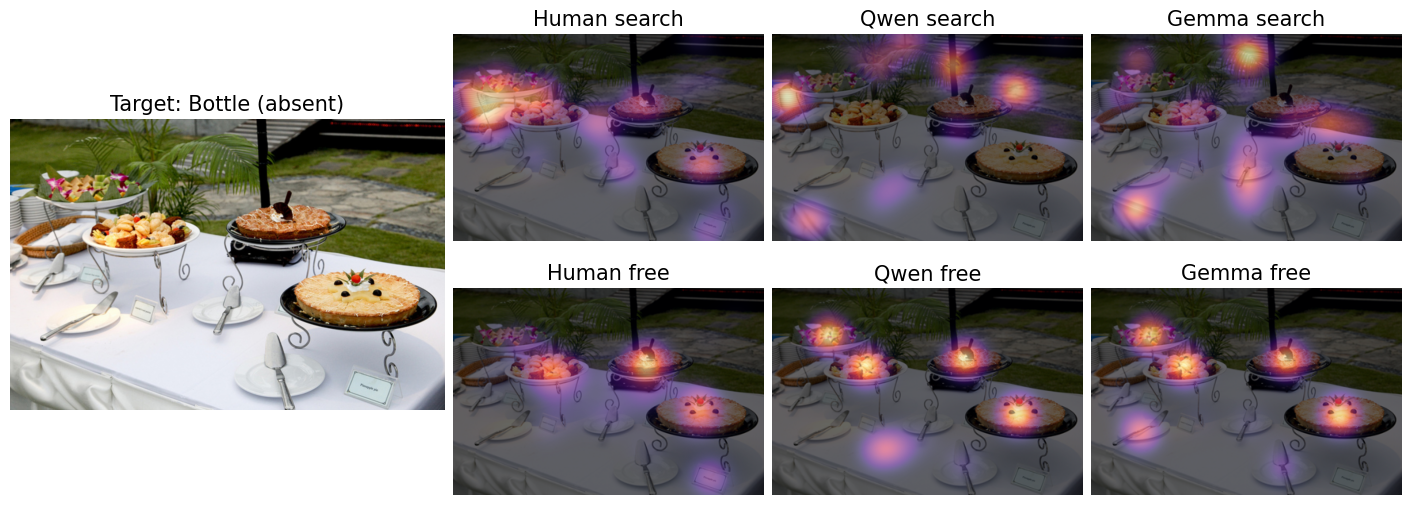

In [44]:
# Plot one representative target-absent image's density maps across humans, Qwen, and Gemma.
ta_example_candidates = sorted(
    set(qwen_ta_output_search_human_density_maps)
    & set(qwen_ta_output_free_human_density_maps)
    & set(qwen_ta_output_search_density_maps)
    & set(qwen_ta_output_free_density_maps)
    & set(gemma_ta_output_search_density_maps)
    & set(gemma_ta_output_free_density_maps)
)

example_picture = ("bottle", "000000085462.jpg")
example_image_path = ANALYSIS.parent / "data" / "COCO-Search18" / "TA-images" / example_picture[0] / example_picture[1]
example_image = Image.open(example_image_path).convert("RGB")
example_image, _, _ = gm.crop_letterbox(example_image)

ta_example_maps = [
    ("Human search", qwen_ta_output_search_human_density_maps[example_picture]),
    ("Qwen search", qwen_ta_output_search_density_maps[example_picture]),
    ("Gemma search", gemma_ta_output_search_density_maps[example_picture]),
    ("Human free", qwen_ta_output_free_human_density_maps[example_picture]),
    ("Qwen free", qwen_ta_output_free_density_maps[example_picture]),
    ("Gemma free", gemma_ta_output_free_density_maps[example_picture]),
]

fig = plt.figure(figsize=(14, 5), constrained_layout=True)
grid = fig.add_gridspec(
    2,
    4,
    width_ratios=[1.4, 1, 1, 1],
    wspace=0,
    hspace=0,
)

original_ax = fig.add_subplot(grid[:, 0])
original_ax.imshow(example_image)
original_ax.set_title("Target: Bottle (absent)", fontsize=15)
original_ax.axis("off")

axes = [fig.add_subplot(grid[row, col]) for row in range(2) for col in range(1, 4)]

for ax, (title, density) in zip(axes, ta_example_maps):
    plot_image = example_image.resize((density.shape[1], density.shape[0]))

    ax.imshow(plot_image, alpha=1)
    ax.imshow(density, cmap="magma", vmin=0, vmax=1, alpha=0.6)
    ax.set_title(title, fontsize=15)
    ax.axis("off")